# 4 Maximum Aposteriori Estimation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import er, rr, d_rr, gd_er, gd_rr, logsigma, classify, optimize

## 4a Gradient Descent

Implement the function returning the regularized risk of logistic
regression, regularized with parameter lambda, in `a02_functions.py`. Then test it
below.

In [2]:
# this should give:
# [15.356163676288993, 261.33830653343193]
[rr(y, Xz, np.linspace(-5, 5, D), 0), rr(y, Xz, np.linspace(-5, 5, D), 1)]

[np.float64(15.356163676288997), np.float64(261.3383065334319)]

Now implement the function to obtain its gradient and test it, in the same manner as
before.

In [3]:
# this should give:
# [array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
#         -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
#         -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
#         -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
#         -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
#          0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
#          0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
#          0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
#          0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
#          0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
#          0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
#         -0.12338248, -0.1357652 ]),
#  array([-5.1798825 , -4.8683588 , -4.91751742, -4.51546757, -4.54757796,
#         -4.36683683, -4.22895983, -3.95292501, -3.78649782, -3.54646647,
#         -3.4659412 , -3.15069088, -3.00581161, -2.75503668, -2.68350882,
#         -2.60359491, -2.39969148, -2.17618797, -2.08021602, -1.78463238,
#         -1.81186225, -1.28926913, -1.34536378, -1.09948179, -0.48372514,
#         -0.33010124, -0.17138588, -0.00646377,  0.11730408,  0.33408312,
#          0.49143526,  0.65810238,  0.82696825,  1.01560443,  1.20432176,
#          1.39885237,  1.62330866,  1.64236985,  1.9145305 ,  2.03905937,
#          2.2369725 ,  2.43957997,  2.6471057 ,  2.76895946,  2.99254023,
#          3.18327961,  3.26895015,  3.48124356,  3.65371288,  3.86671288,
#          4.01311456,  3.97064714,  4.08847392,  4.45022245,  4.59318583,
#          4.69804609,  4.8642348 ])]
[d_rr(y, Xz, np.linspace(-5, 5, D), 0), d_rr(y, Xz, np.linspace(-5, 5, D), 1)]

[array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
        -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
        -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
        -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
        -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
         0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
         0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
         0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
         0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
         0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
         0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
        -0.12338248, -0.1357652 ]),
 array([-5.1798825 , -4.8683588 , -4.91751742, -4.51546757, -4.54757796,
        -4.36683683, -4.22895983, -3.95292501, -3.78649782, -3.54646647,
        -3.4659

Now define the (f,update) tuple handed to the `optimize` function for gradient descent
on logistic regression with L2 regularization. Then run it below.

In [4]:
# let's run!
lambda_ = 0.1
np.random.seed(0)
w0 = np.random.normal(size=D)
wz_gd_rr, vz_gd_rr, ez_gd_rr = optimize(
    gd_rr(y, Xz, lambda_=lambda_), w0, nepochs=500, verbose=True
)

Epoch   0: f=     5.521, eps=0.010000000
Epoch   1: f=     5.507, eps=0.010500000
Epoch   2: f=     5.492, eps=0.011025000
Epoch   3: f=     5.476, eps=0.011576250
Epoch   4: f=     5.459, eps=0.012155063
Epoch   5: f=     5.441, eps=0.012762816
Epoch   6: f=     5.423, eps=0.013400956
Epoch   7: f=     5.404, eps=0.014071004
Epoch   8: f=     5.384, eps=0.014774554
Epoch   9: f=     5.364, eps=0.015513282
Epoch  10: f=     5.342, eps=0.016288946
Epoch  11: f=     5.319, eps=0.017103394
Epoch  12: f=     5.295, eps=0.017958563
Epoch  13: f=     5.271, eps=0.018856491
Epoch  14: f=     5.245, eps=0.019799316
Epoch  15: f=     5.218, eps=0.020789282
Epoch  16: f=     5.190, eps=0.021828746
Epoch  17: f=     5.161, eps=0.022920183
Epoch  18: f=     5.130, eps=0.024066192
Epoch  19: f=     5.099, eps=0.025269502
Epoch  20: f=     5.065, eps=0.026532977
Epoch  21: f=     5.031, eps=0.027859626
Epoch  22: f=     4.995, eps=0.029252607
Epoch  23: f=     4.957, eps=0.030715238
Epoch  24: f=   

## 4b Effect of Prior

          training_empirical_risk  test_mean_log_loss  test_accuracy  weight_norm
lambda                                                                           
0.000                    0.214451            0.279155       0.918620     8.944790
0.001                    0.221073            0.282985       0.919271     4.316131
0.010                    0.242109            0.290380       0.920573     2.526085
0.100                    0.320655            0.349193       0.911458     1.177620
1.000                    0.495681            0.502987       0.893229     0.378915
10.000                   0.651671            0.652205       0.887370     0.062831
100.000                  0.688424            0.688465       0.886068     0.006855
1000.000                 0.692668            0.692672       0.886068     0.000692


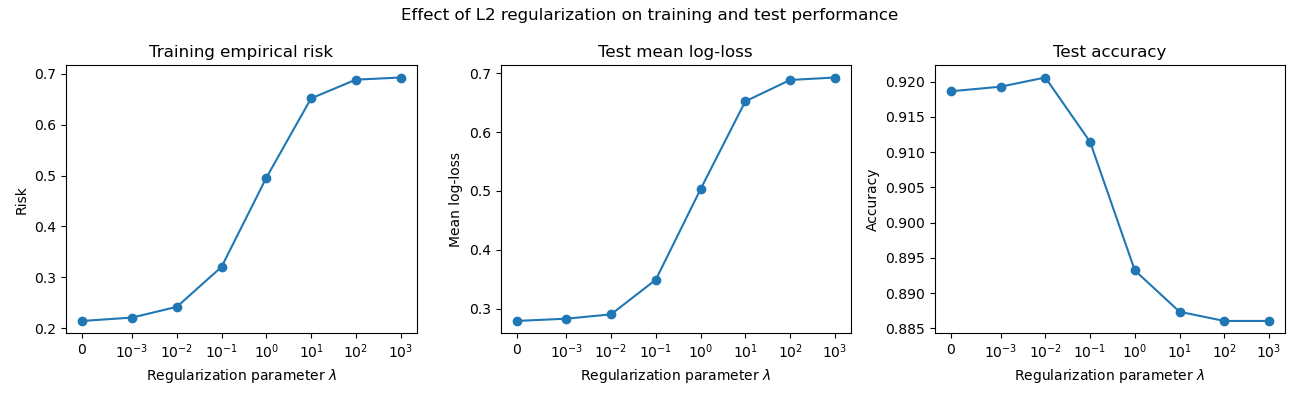

In [5]:
# YOUR CODE HERE
from pathlib import Path

regularization_values = np.array([0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0])
task4_models = {}
task4_rows = []
for regularization in regularization_values:
    fitted, risk_history, step_history = optimize(
        gd_rr(y, Xz, lambda_=float(regularization)),
        w0.copy(),
        nepochs=500,
        verbose=False,
    )
    task4_models[float(regularization)] = fitted
    test_labels = classify(Xtestz, fitted)
    task4_rows.append(
        {
            "lambda": regularization,
            "training_empirical_risk": er(y, Xz, fitted),
            "test_mean_log_loss": er(ytest, Xtestz, fitted),
            "test_accuracy": sklearn.metrics.accuracy_score(ytest, test_labels),
            "weight_norm": np.linalg.norm(fitted),
        }
    )

task4_metrics = pd.DataFrame(task4_rows).set_index("lambda")
print(task4_metrics.round(6).to_string())

task4_results = Path("../results/task4")
task4_results.mkdir(parents=True, exist_ok=True)
task4_metrics.to_csv(task4_results / "metrics.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric, title in zip(
    axes,
    ["training_empirical_risk", "test_mean_log_loss", "test_accuracy"],
    ["Training empirical risk", "Test mean log-loss", "Test accuracy"],
):
    ax.plot(task4_metrics.index, task4_metrics[metric], marker="o")
    ax.set_xscale("symlog", linthresh=0.001)
    ax.set(xlabel=r"Regularization parameter $\lambda$", title=title)
axes[0].set_ylabel("Risk")
axes[1].set_ylabel("Mean log-loss")
axes[2].set_ylabel("Accuracy")
fig.suptitle("Effect of L2 regularization on training and test performance")
fig.tight_layout()
fig.savefig(task4_results / "regularization_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

## 4c Composition of Weight Vector

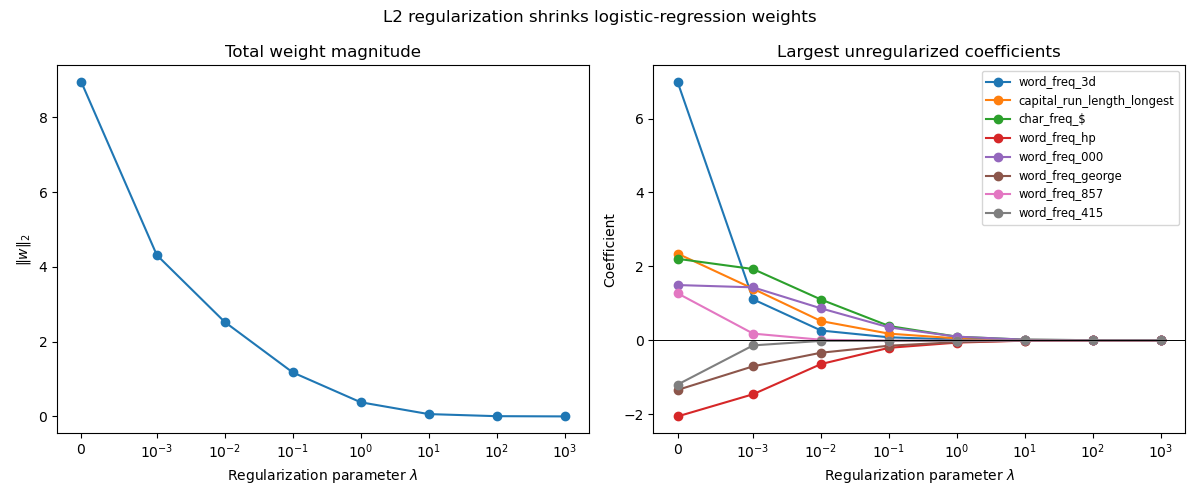

Largest coefficients at lambda=0, followed across the regularization grid:
          word_freq_3d  capital_run_length_longest  char_freq_$  word_freq_hp  word_freq_000  word_freq_george  word_freq_857  word_freq_415
0.000           6.9897                      2.3443       2.2043       -2.0623         1.4938           -1.3452         1.2697        -1.2001
0.001           1.1073                      1.3930       1.9267       -1.4621         1.4317           -0.7060         0.1791        -0.1393
0.010           0.2622                      0.5180       1.1009       -0.6445         0.8620           -0.3378         0.0128        -0.0184
0.100           0.0786                      0.1783       0.3853       -0.2051         0.3477           -0.1484        -0.0128        -0.0147
1.000           0.0199                      0.0499       0.0956       -0.0645         0.0959           -0.0520        -0.0143        -0.0144
10.000          0.0027                      0.0085       0.0148       -0.0115  

In [6]:
# YOUR CODE HERE
weight_matrix = np.vstack([task4_models[float(value)] for value in regularization_values])
weight_norms = np.linalg.norm(weight_matrix, axis=1)
strongest_features = np.argsort(np.abs(weight_matrix[0]))[-8:]
strongest_features = strongest_features[np.argsort(np.abs(weight_matrix[0, strongest_features]))[::-1]]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(regularization_values, weight_norms, marker="o")
axes[0].set_xscale("symlog", linthresh=0.001)
axes[0].set(xlabel=r"Regularization parameter $\lambda$", ylabel=r"$\|w\|_2$", title="Total weight magnitude")
for feature_index in strongest_features:
    axes[1].plot(regularization_values, weight_matrix[:, feature_index], marker="o", label=features[feature_index])
axes[1].set_xscale("symlog", linthresh=0.001)
axes[1].set(xlabel=r"Regularization parameter $\lambda$", ylabel="Coefficient", title="Largest unregularized coefficients")
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].legend(fontsize="small")
fig.suptitle("L2 regularization shrinks logistic-regression weights")
fig.tight_layout()
fig.savefig(task4_results / "weight_composition.png", dpi=180, bbox_inches="tight")
plt.show()

selected_weights = pd.DataFrame(
    weight_matrix[:, strongest_features],
    index=regularization_values,
    columns=features[strongest_features],
)
selected_weights.to_csv(task4_results / "selected_weights.csv")
print("Largest coefficients at lambda=0, followed across the regularization grid:")
print(selected_weights.round(4).to_string())
print("All coefficient norms:")
print(pd.Series(weight_norms, index=regularization_values, name="L2 norm").round(4).to_string())